In [1]:
import scanpy as sc
adata_HD = sc.read("../h5ad/adata_HD.h5ad")
adata_HD_L = adata_HD[adata_HD.obs["batch"]=="nS06"]
sc.pp.normalize_total(adata_HD_L, target_sum=1e6)
sc.pp.log1p(adata_HD_L)

/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


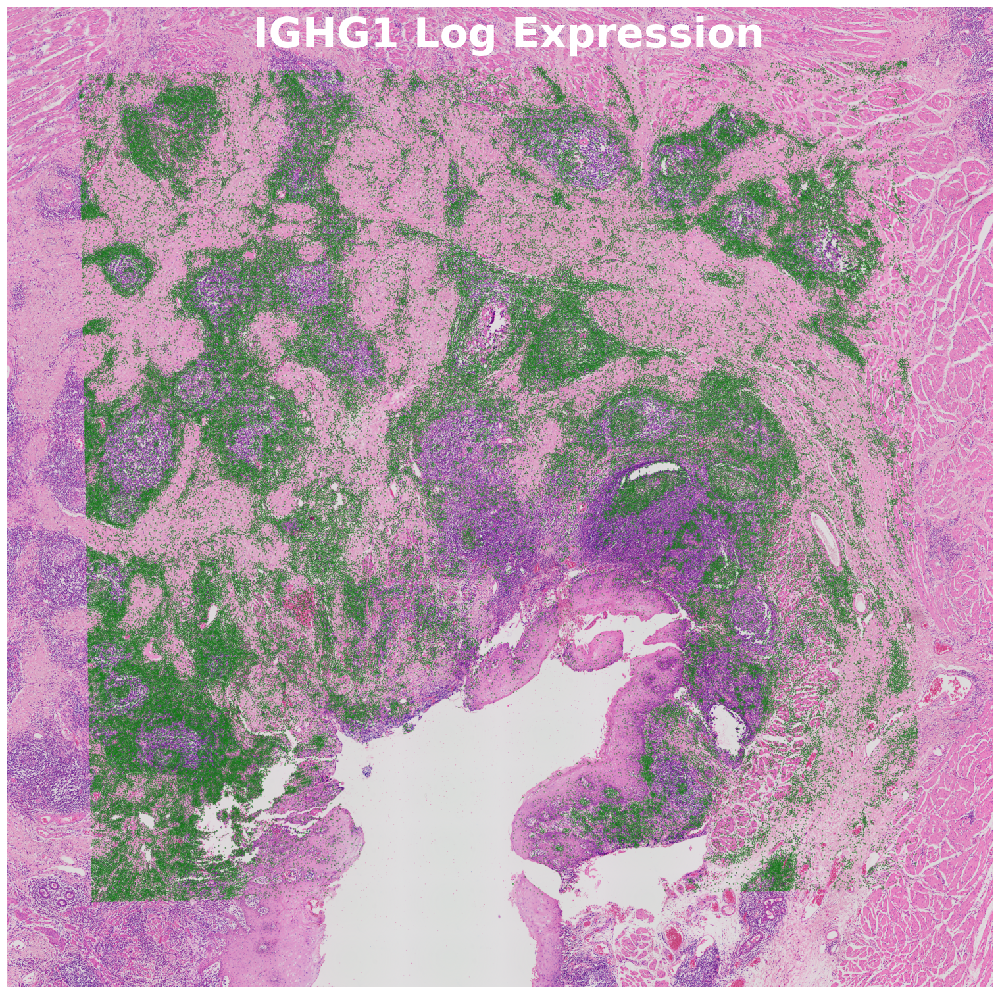

In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

# === 1. Setup and read the image ===
Image.MAX_IMAGE_PIXELS = None
image_path = '../organize_photos/nS06.tif'
img = mpimg.imread(image_path)

# === 2. Calculate the score for each spot ===
gene_list = ["IGHG1"]

# 1. Filter valid genes
valid_genes = [g for g in gene_list if g in adata_HD_L.var_names]
if not valid_genes:
    raise ValueError("Genes in the gene list are not present in adata")

# 2. Get data
all_coords = adata_HD_L.obsm["spatial"]
sub_matrix = adata_HD_L[:, valid_genes].X

# 3. Convert to dense array
if hasattr(sub_matrix, 'toarray'):
    dense_data = sub_matrix.toarray()
else:
    dense_data = np.array(sub_matrix)

# 4. Calculate mean expression
gene_scores = np.mean(dense_data, axis=1)

# === 4. Calculate the Bounding Box ===
all_x = all_coords[:, 0]
all_y = all_coords[:, 1]

# === 5. Plot ===
plt.figure(figsize=(15, 15))
plt.imshow(img)

# Normalize expression values to 0~0.5 as transparency
norm_alpha = gene_scores / (2*np.max(gene_scores)) 

plt.scatter(
    all_x, all_y, 
    c='green',           # Color fixed to green
    alpha=norm_alpha,    # Transparency varies with expression level
    s=0.5                # Spot size
)

#plt.gca().invert_yaxis()

plt.axis('off')
plt.text(0.25, 0.99, "IGHG1 Log Expression", transform=plt.gca().transAxes, 
         fontsize=45, fontweight='bold', color='white', 
         ha='left', va='top')
plt.tight_layout(pad=0)
plt.show()

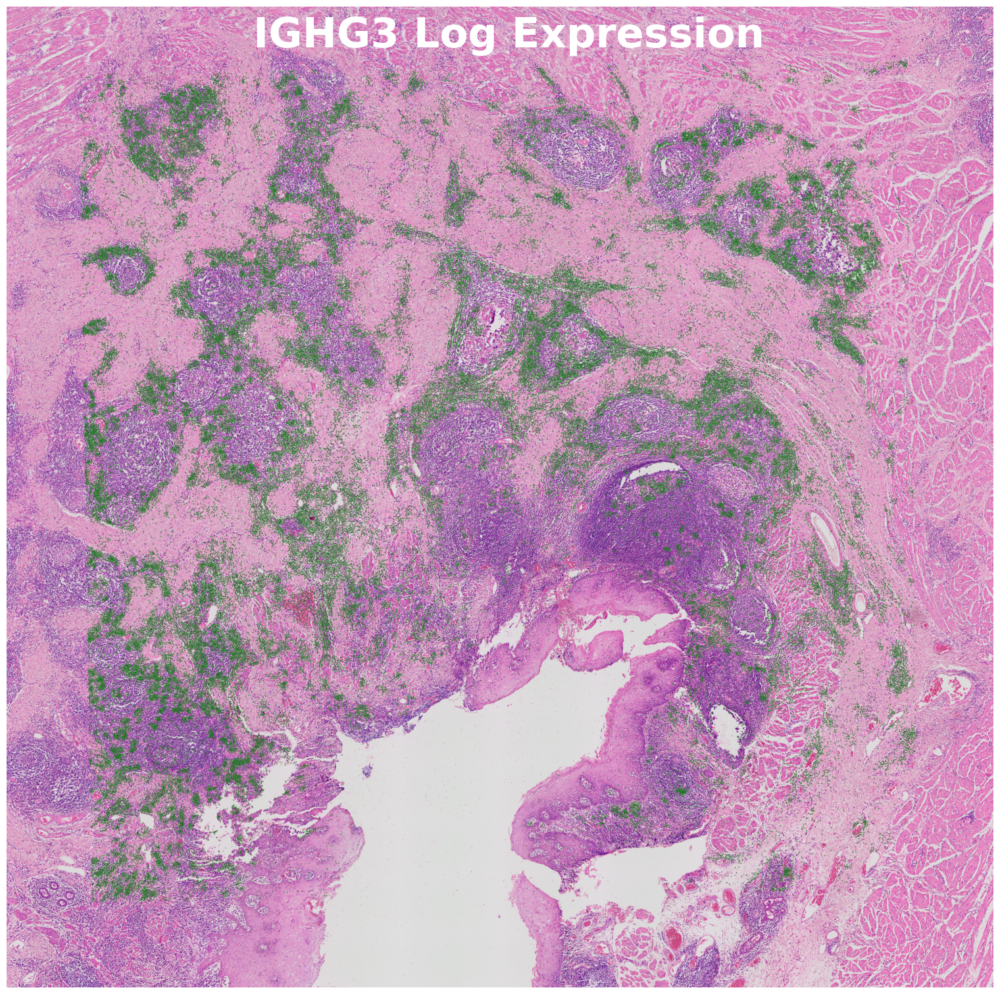

In [3]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from PIL import Image

# === 1. Setup and read the image ===
Image.MAX_IMAGE_PIXELS = None
image_path = '../organize_photos/nS06.tif'
img = mpimg.imread(image_path)

# === 2. Calculate the score for each spot ===
gene_list = ["IGHG3"]

# 1. Filter valid genes
valid_genes = [g for g in gene_list if g in adata_HD_L.var_names]
if not valid_genes:
    raise ValueError("Genes in the gene list are not present in adata")

# 2. Get data
all_coords = adata_HD_L.obsm["spatial"]
sub_matrix = adata_HD_L[:, valid_genes].X

# 3. Convert to dense array
if hasattr(sub_matrix, 'toarray'):
    dense_data = sub_matrix.toarray()
else:
    dense_data = np.array(sub_matrix)

# 4. Calculate mean expression
gene_scores = np.mean(dense_data, axis=1)

# === 4. Calculate the Bounding Box ===
all_x = all_coords[:, 0]
all_y = all_coords[:, 1]

# === 5. Plot ===
plt.figure(figsize=(15, 15))
plt.imshow(img)

# Normalize expression values to 0~0.5 as transparency
norm_alpha = gene_scores / (2*np.max(gene_scores)) 

plt.scatter(
    all_x, all_y, 
    c='green',           # Color fixed to green
    alpha=norm_alpha,    # Transparency varies with expression level
    s=0.5                # Spot size
)

#plt.gca().invert_yaxis()

plt.axis('off')
plt.text(0.25, 0.99, "IGHG3 Log Expression", transform=plt.gca().transAxes, 
         fontsize=45, fontweight='bold', color='white', 
         ha='left', va='top')
plt.tight_layout(pad=0)
plt.show()